# Lab 5 Task 4: Real N310 OFDM Link

Verify file sizes and finite-transmission accounting, acquire uncropped files with the supplied GNU Radio graphs, and run the same receiver used in Task 3 on data captured on the N310


In [1]:
from pathlib import Path
import json
import os
import sys
import numpy as np
from IPython.display import Image, display
import IPython.core.pylabtools as pylabtools

# Matplotlib 3.6 expects this compatibility table, which newer IPython omits.
if not hasattr(pylabtools, "backend2gui"):
    pylabtools.backend2gui = {}

def locate_lab_root():
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "support" / "lab5_dsp.py").is_file():
            return base
    raise FileNotFoundError("Open this notebook from its Lab 5 folder.")

LAB_ROOT = locate_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
WORK_DIR = LAB_ROOT / "work"
FIGURE_DIR = WORK_DIR / "figures"
WAVEFORM_DIR = WORK_DIR / "waveforms"
CAPTURE_DIR = Path(os.environ.get("ECE7377_LAB5_CAPTURE_DIR", WORK_DIR / "captures"))
for path in (FIGURE_DIR, WAVEFORM_DIR, CAPTURE_DIR):
    path.mkdir(parents=True, exist_ok=True)

import lab5_dsp as lab
import lab5_tools

print("Lab root:", LAB_ROOT)
print("Capture directory:", CAPTURE_DIR)


Lab root: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5
Capture directory: /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures


## Finite-file and capture calculations


In [2]:
sample_rate_sps = 1_000_000
period_samples = 8192
repeat_count = 13
warmup_periods = 1
acquisition_lead_samples = 2_000_000
capture_seconds = 15.0

# Exact counts
payload_burst_samples = repeat_count * period_samples
transmit_samples = acquisition_lead_samples + payload_burst_samples
transmit_bytes = transmit_samples * 8          # complex64

capture_samples = int(capture_seconds * sample_rate_sps)
capture_bytes = capture_samples * 8            # complex64

expected_frames = repeat_count - warmup_periods

print("OFDM burst samples:", payload_burst_samples)
print("guarded TX samples and bytes:", transmit_samples, transmit_bytes)
print("RX samples and bytes:", capture_samples, capture_bytes)
print("graded frames:", expected_frames)

OFDM burst samples: 106496
guarded TX samples and bytes: 2106496 16851968
RX samples and bytes: 15000000 120000000
graded frames: 12


In [3]:
assert payload_burst_samples == 106_496
assert transmit_samples == 2_106_496
assert transmit_bytes == 16_851_968
assert capture_samples == 15_000_000
assert capture_bytes == 120_000_000
assert expected_frames == 12
print("Hardware accounting passed.")


Hardware accounting passed.


## Build the finite transmitter file and metadata


<span style="color:#165696"><b>Report.</b> Confirm the TX file is 16,851,968 bytes. </span>

In [7]:
!ls -la $WAVEFORM_DIR/task4_ofdm_13period_c64.dat

-rw-r--r--  1 marcpham  staff  16851968 Oct 27 20:29 /Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/waveforms/task4_ofdm_13period_c64.dat


In [4]:
tx_gains_db = (40, 45, 50)
rx_gain_db = 60

prepared = lab5_tools.prepare_hardware_experiment(
    WAVEFORM_DIR,
    CAPTURE_DIR,
    tx_gains_db=tx_gains_db,
    rx_gain_db=rx_gain_db,
)
print(json.dumps(prepared, indent=2))
assert prepared["waveform_bytes"] == 16_851_968


{
  "waveform_path": "/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/waveforms/task4_ofdm_13period_c64.dat",
  "waveform_bytes": 16851968,
  "summary_path": "/Users/marcpham/jupyter_notebook_files/Embedded-Wireless-Design-Labs/Lab5/work/captures/lab5_measurement_summary.json",
  "summary": {
    "waveform": {
      "tx_gains_db": [
        40,
        45,
        50
      ],
      "measurement_periods": 12,
      "warmup_periods": 1,
      "repeat_count": 13,
      "capture_duration_s": 15.0,
      "capture_samples": 15000000,
      "sample_rate_sps": 1000000.0,
      "center_frequency_hz": 2450000000.0,
      "rx_gain_db": 60.0,
      "period_samples": 8192,
      "active_frame_samples": 2080,
      "acquisition_lead_samples": 2000000,
      "finite_tx_samples": 2106496,
      "digital_peak": 0.10000000149011612,
      "period_sha256": "a1e8eceb01c8c6d9eeb0d374cd2cbb2668a17f9f90a3f828317c2bfe7094eaba",
      "file_sha256": "f957d2fa3fb606170cf1daebe12a2

## GNU Radio acquisition

Open `flowgraphs/lab5_finite_ofdm_receiver.grc` on the RX desktop and `flowgraphs/lab5_finite_ofdm_transmitter.grc` on the TX desktop. Verify the assigned device argument, subdevice, antenna, 1 MS/s rate, 2.45 GHz center, gain, and file paths.

1. With TX stopped, set the RX output to `work/captures/lab5_noise_c64.dat`, set the capture to 0.25 seconds, and run RX once.
2. Restore the RX capture to 15 seconds.
3. For each assigned TX gain, set the RX output to `work/captures/lab5_ofdm_tx<gain>_c64.dat`.
4. Start RX first, then TX. Do not crop the raw file.
5. Confirm that the noise file is 2,000,000 bytes and every gain file is 120,000,000 bytes.


<span style="color:#165696"><b>Report.</b> Include the TX and RX flowgraphs and verify every hardware field. </span>

Transmitter Flowgraph

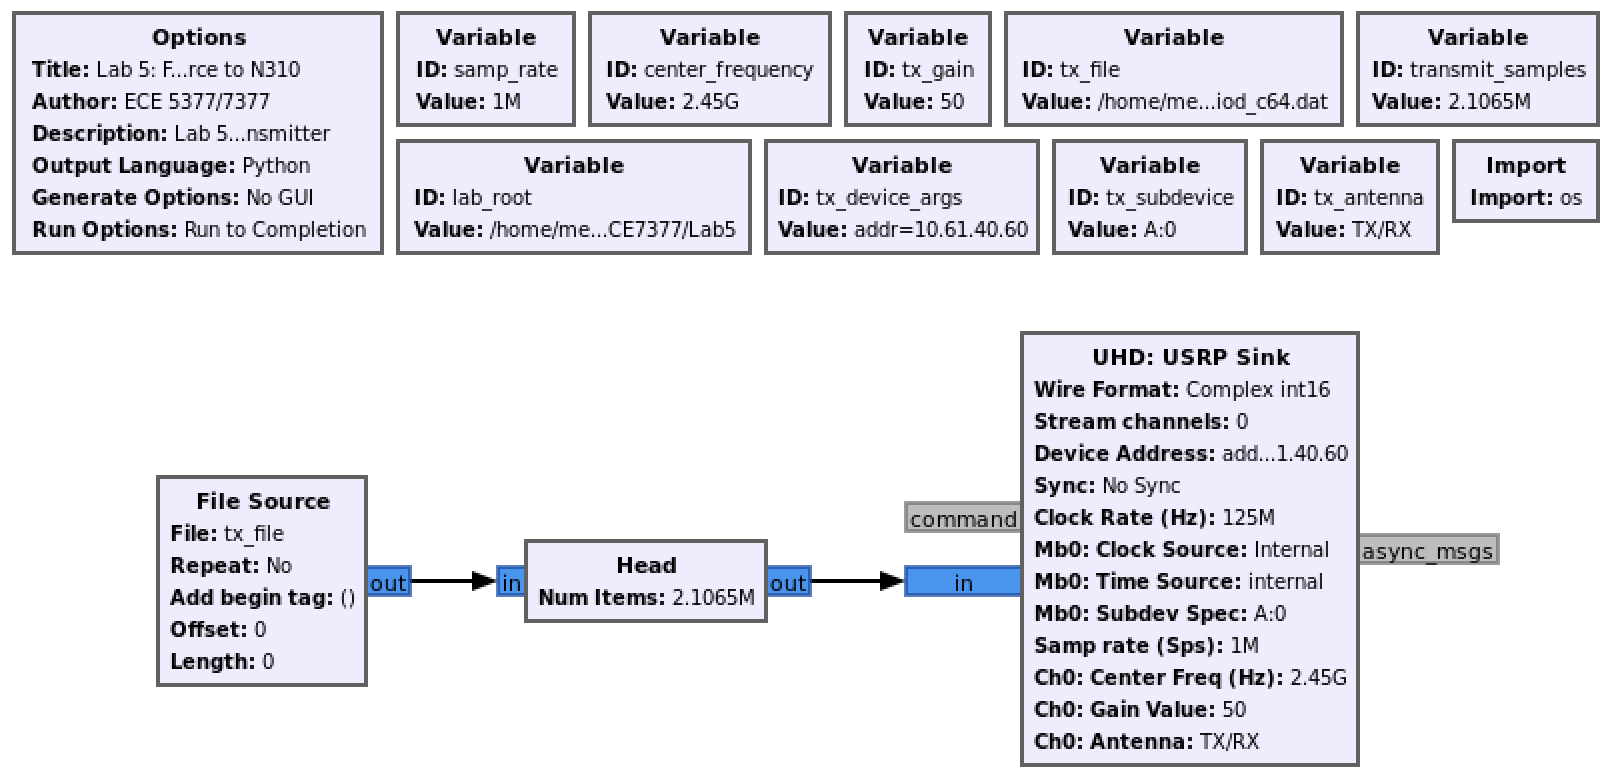

Receiver Flowgraph

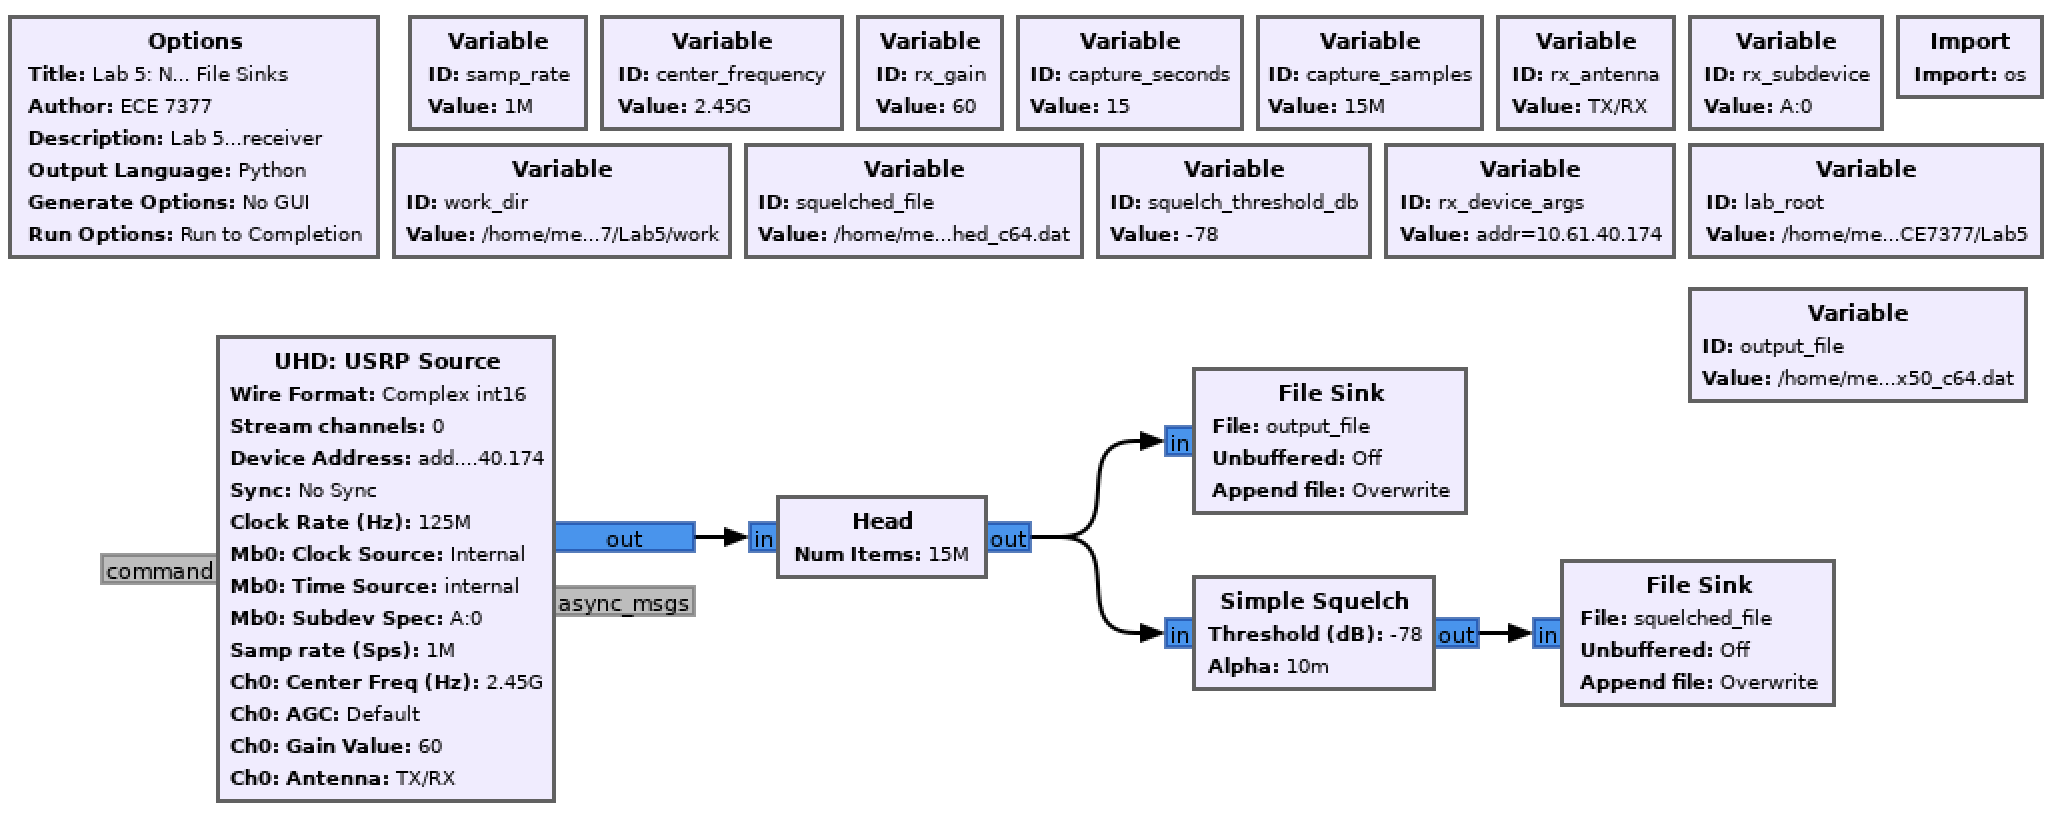

<span style="color:#165696"><b>Report.</b> Save the TX and RX console logs. </span>

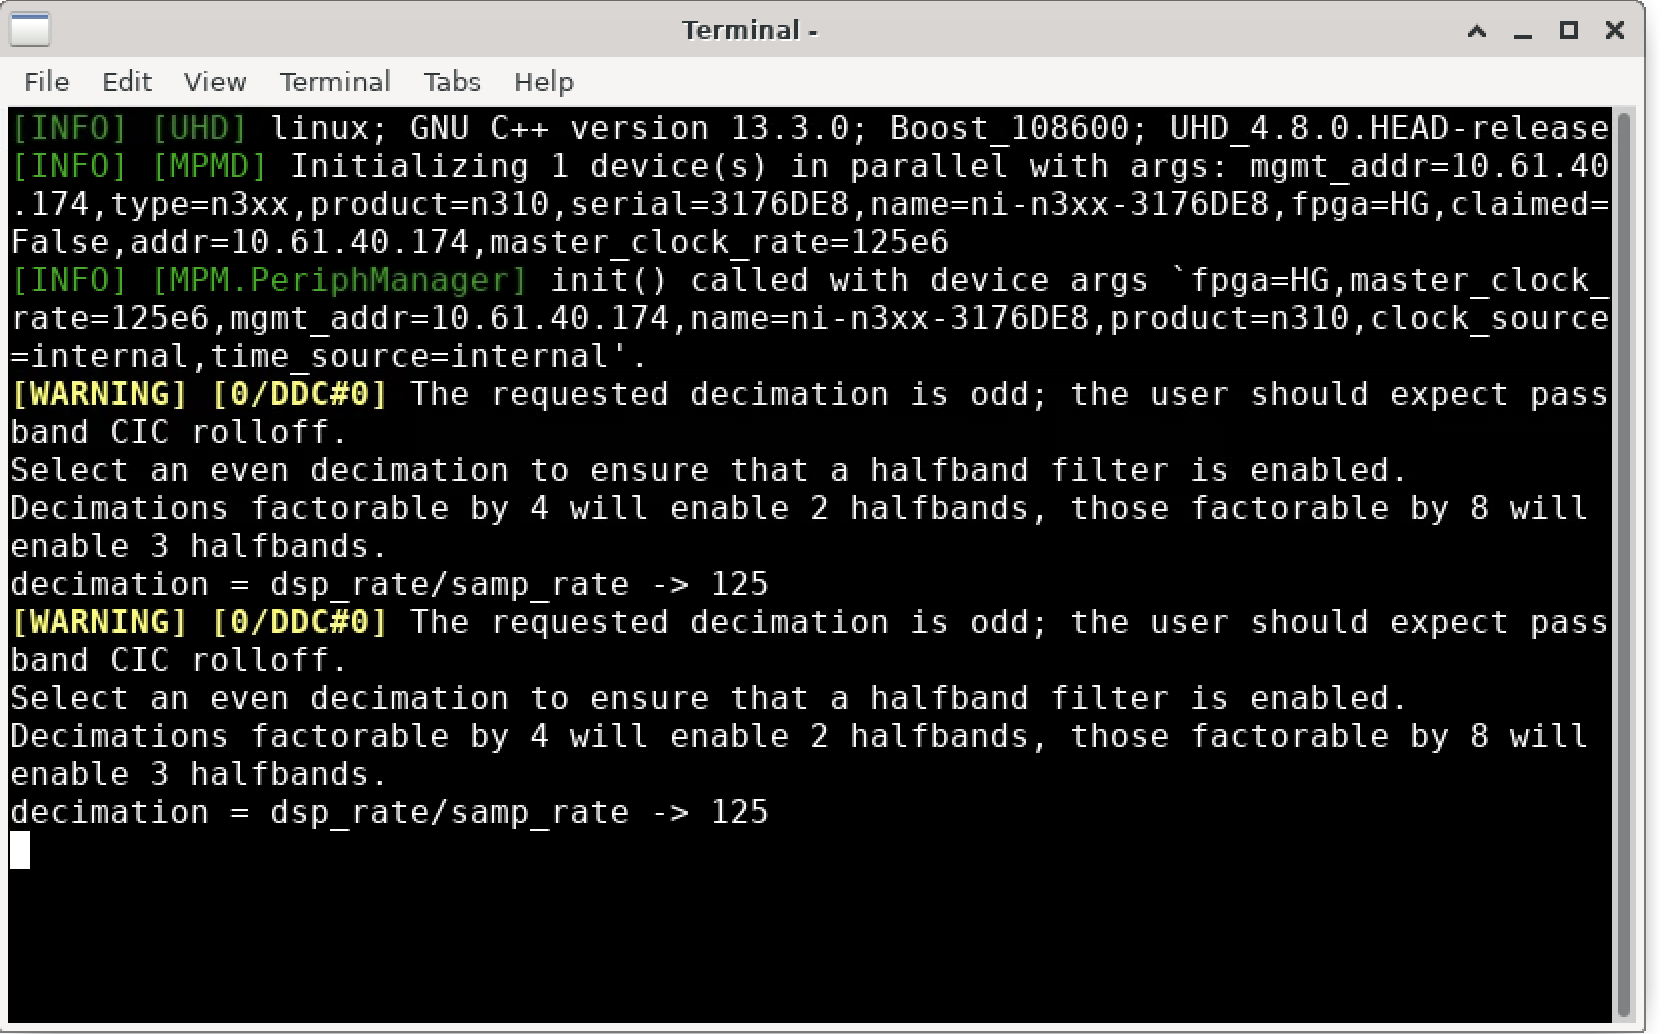

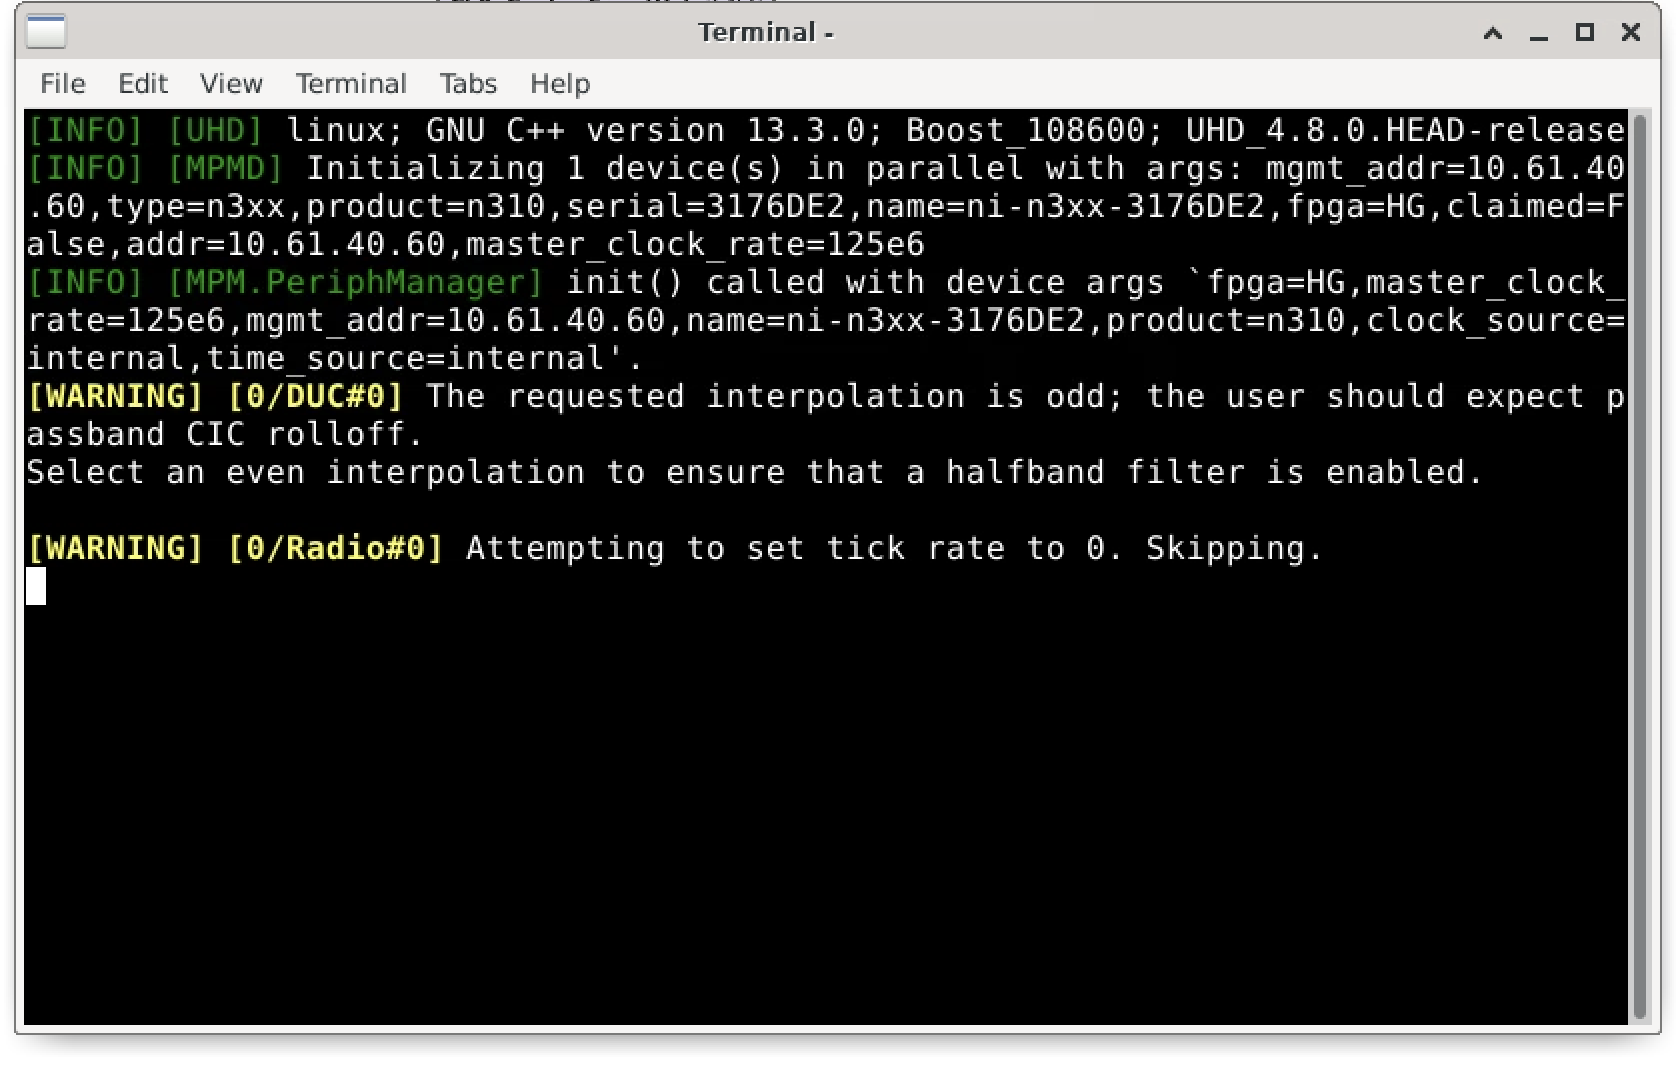

## Analyze the uncropped hardware data


<span style="color:#165696"><b>Report.</b> Confirm the noise file is 2,000,000 bytes. Confirm that the three gain files are 120,000,000 bytes each. </span>

In [12]:
!ls -la $CAPTURE_DIR 

total 941424
drwxr-xr-x  9 marcpham  staff        288 Oct 27 21:22 .
drwxr-xr-x  5 marcpham  staff        160 Oct 26 19:37 ..
drwxr-xr-x  2 marcpham  staff         64 Oct 27 21:22 .ipynb_checkpoints
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_inspection_squelched_c64.dat
-rw-r--r--  1 marcpham  staff        678 Oct 27 20:29 lab5_measurement_summary.json
-rw-r--r--  1 marcpham  staff    2000000 Oct 27 21:22 lab5_noise_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx40_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx45_c64.dat
-rw-r--r--  1 marcpham  staff  120000000 Oct 27 21:22 lab5_ofdm_tx50_c64.dat


<span style="color:#165696"><b>Report.</b> Report detected frames, analyzed frames, detection rate, BER, PER, EVM, CFO mean and standard deviation, channel power, and estimated SNR for each gain. </span>

In [8]:
summary_path = CAPTURE_DIR / "lab5_measurement_summary.json"
required = [summary_path, CAPTURE_DIR / "lab5_noise_c64.dat"]
if not all(path.exists() for path in required):
    raise FileNotFoundError("Capture the noise and three gain files before running this cell.")

hardware = lab5_tools.analyze_hardware(CAPTURE_DIR, FIGURE_DIR)
for gain_name, row in hardware["gain_results"].items():
    print(gain_name, json.dumps(row["aggregate"], indent=2))


tx40 {
  "detected_frames_including_warmup": 13,
  "analyzed_frames": 12,
  "detection_rate": 1.0,
  "bit_errors": 0,
  "ber": 0.0,
  "packet_error_rate": 0.0,
  "evm_rms": 0.038839613670685225,
  "cfo_mean_hz": 10.922422722624006,
  "cfo_std_hz": 59.23768095550998,
  "fine_correlation_mean": 0.8526015275671299,
  "channel_power": 1.685848199387624e-05,
  "snr_estimate_db": 35.20337873041737,
  "capture_peak": 0.009464920498430729,
  "clipped_sample_count": 0
}
tx45 {
  "detected_frames_including_warmup": 13,
  "analyzed_frames": 12,
  "detection_rate": 1.0,
  "bit_errors": 0,
  "ber": 0.0,
  "packet_error_rate": 0.0,
  "evm_rms": 0.026604217273013833,
  "cfo_mean_hz": 43.320241916776716,
  "cfo_std_hz": 39.03098258387305,
  "fine_correlation_mean": 0.8730506530519149,
  "channel_power": 5.4011536419302364e-05,
  "snr_estimate_db": 40.260059380849796,
  "capture_peak": 0.018056463450193405,
  "clipped_sample_count": 0
}
tx50 {
  "detected_frames_including_warmup": 13,
  "analyzed_frame

<span style="color:#165696"><b>Report.</b> Show one frame from coarse acquisition through CRC. </span>

Example frame processing showing coarse acquisition using the repeated-preamble metric, fine timing synchronization using cyclic-prefix correlation, FFT demodulation, channel estimation and zero-forcing equalization, pilot-based common phase error correction, and successful packet recovery with CRC pass.

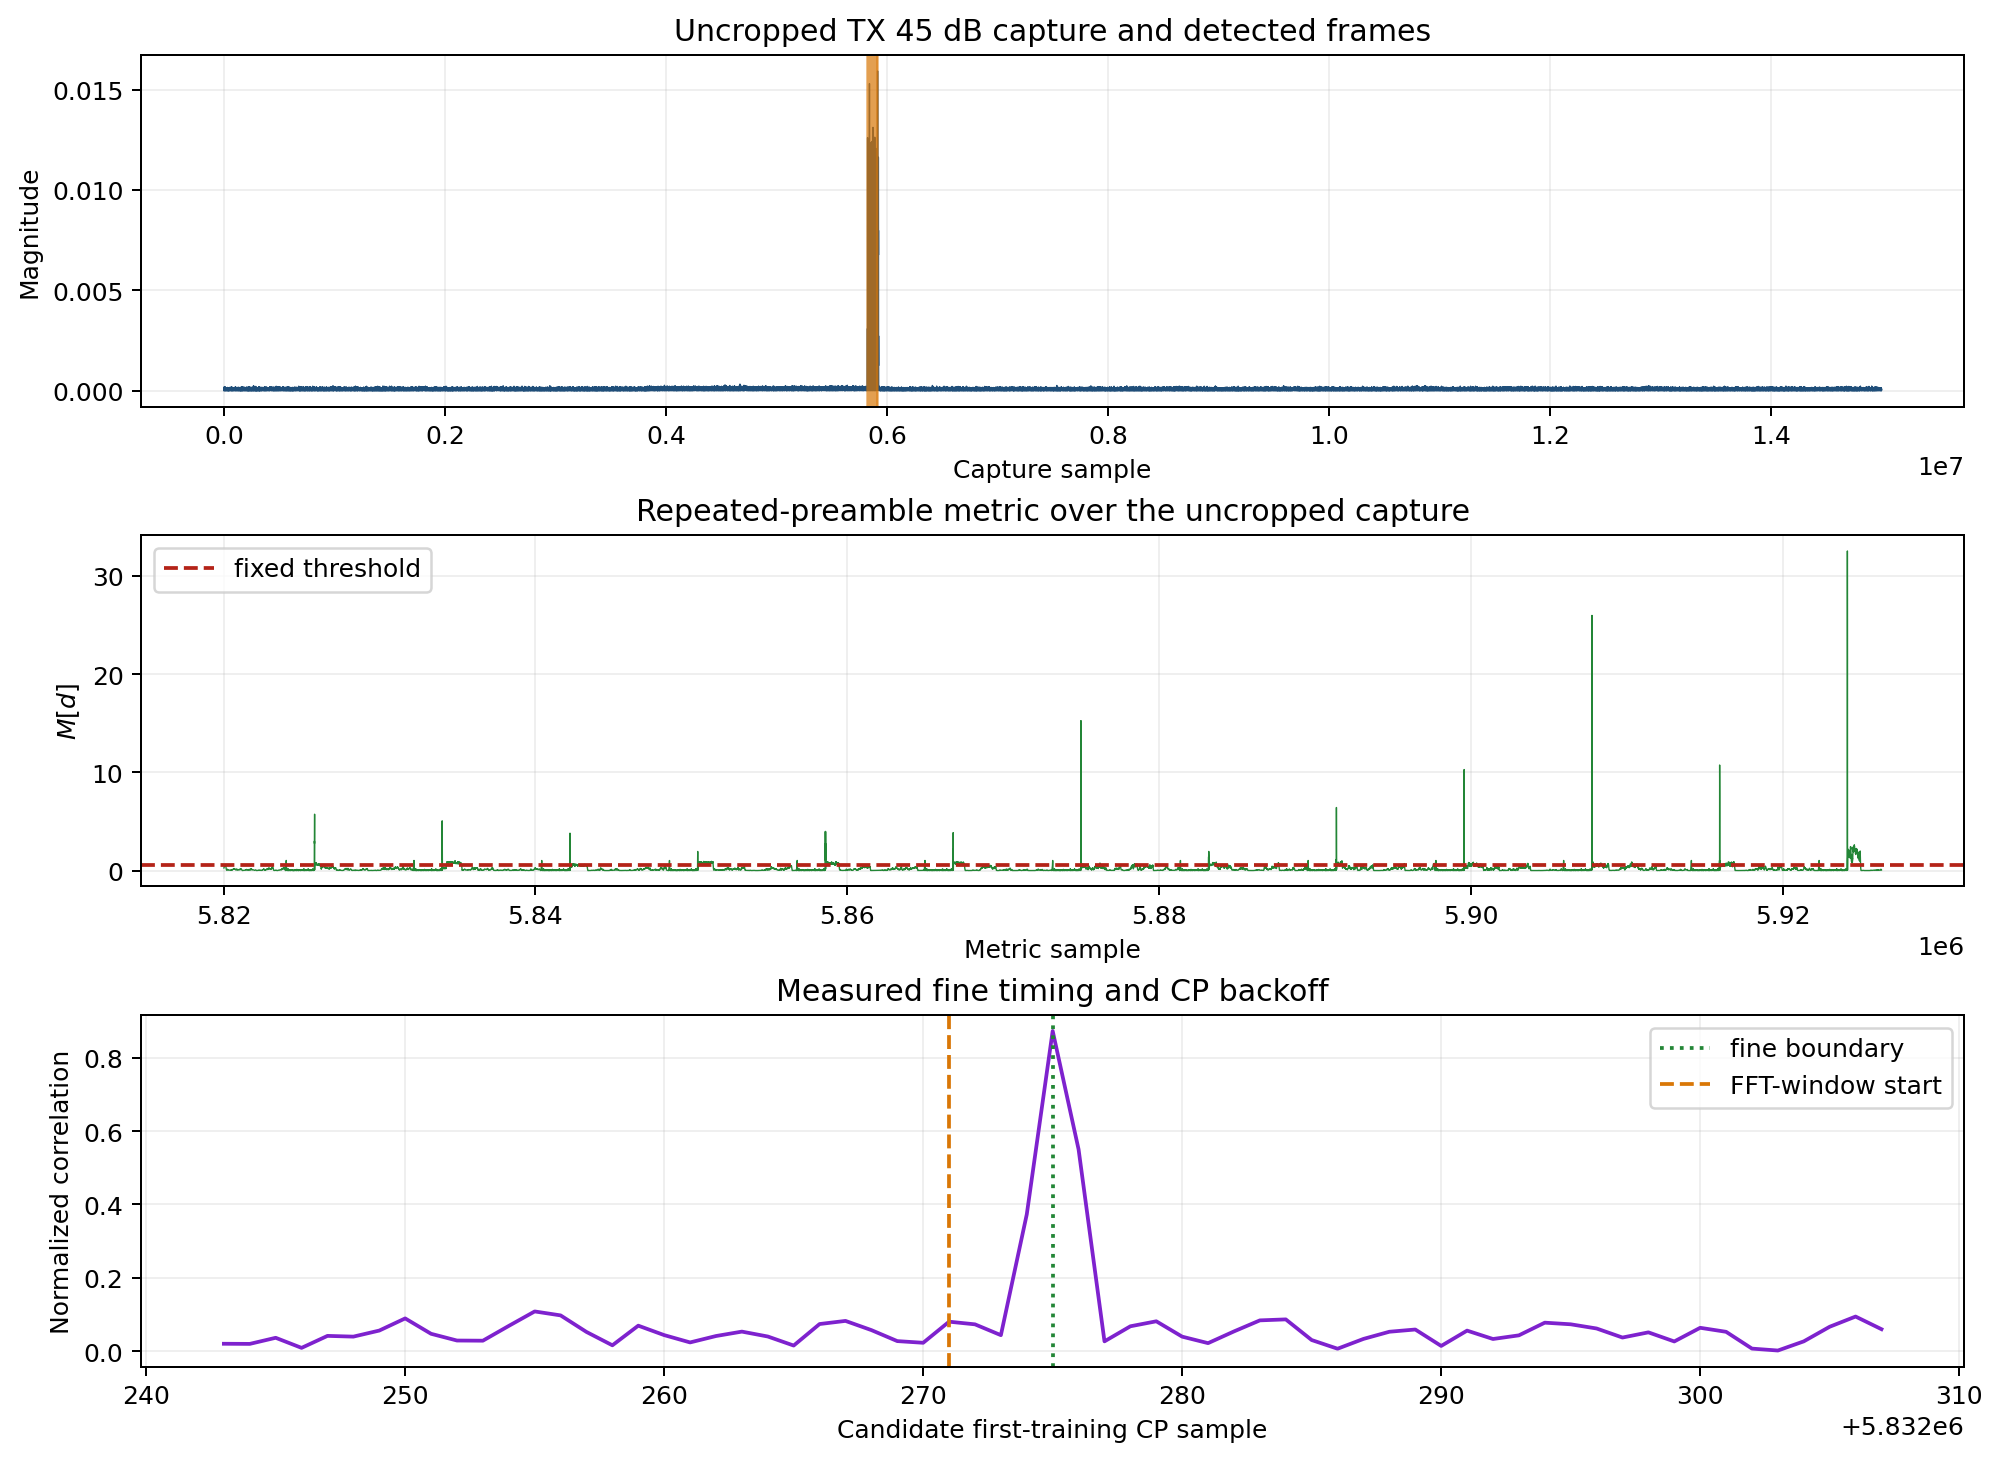

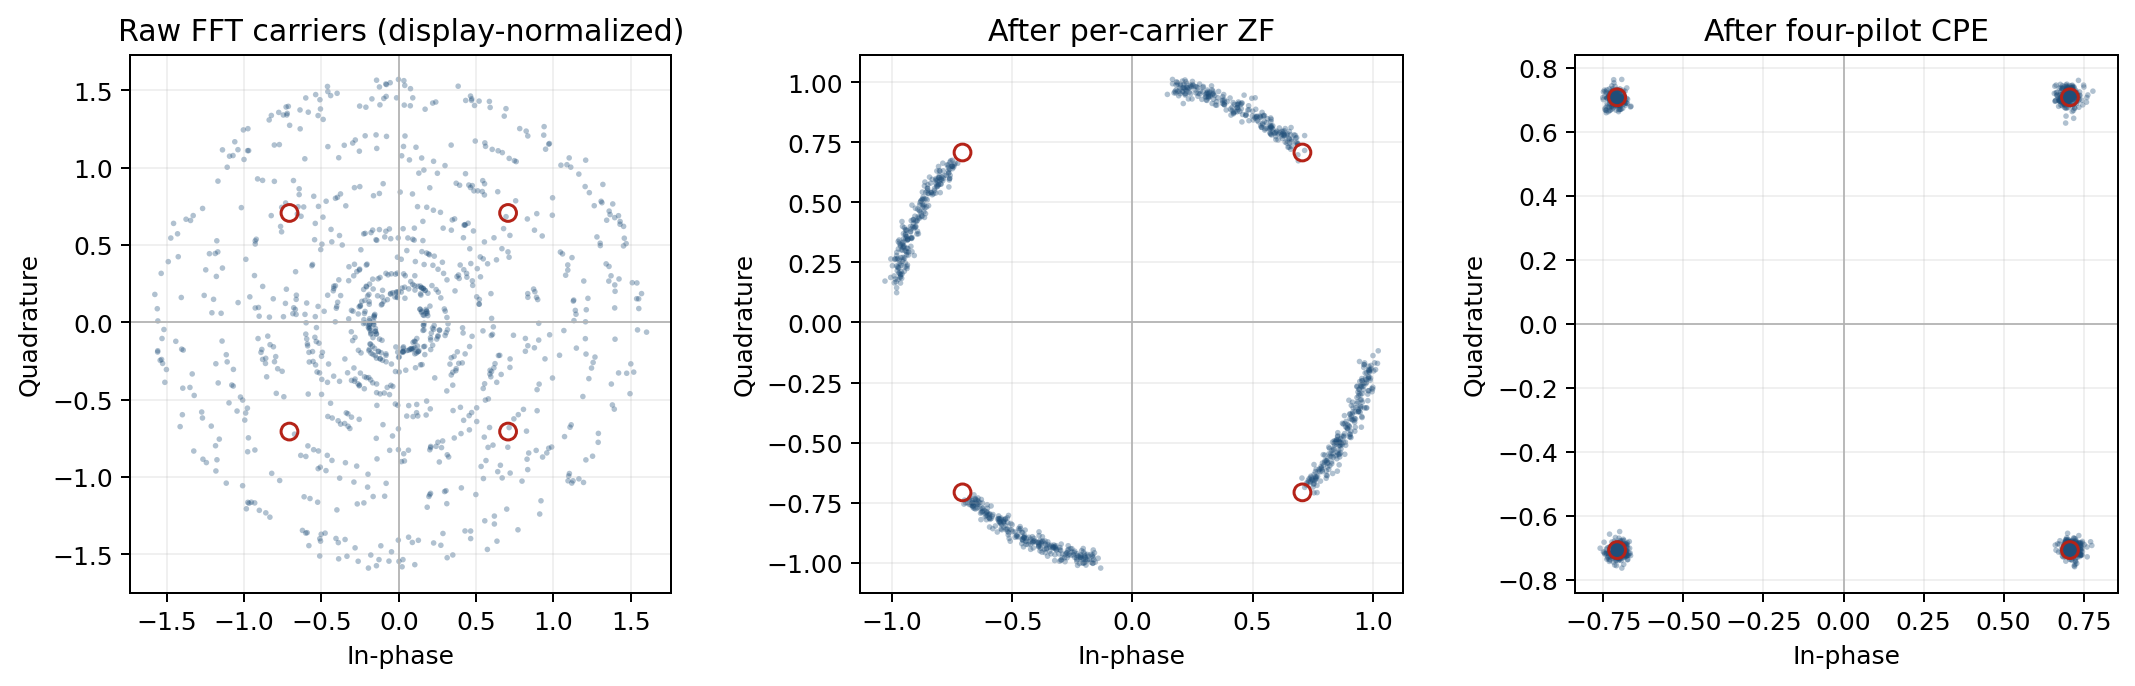

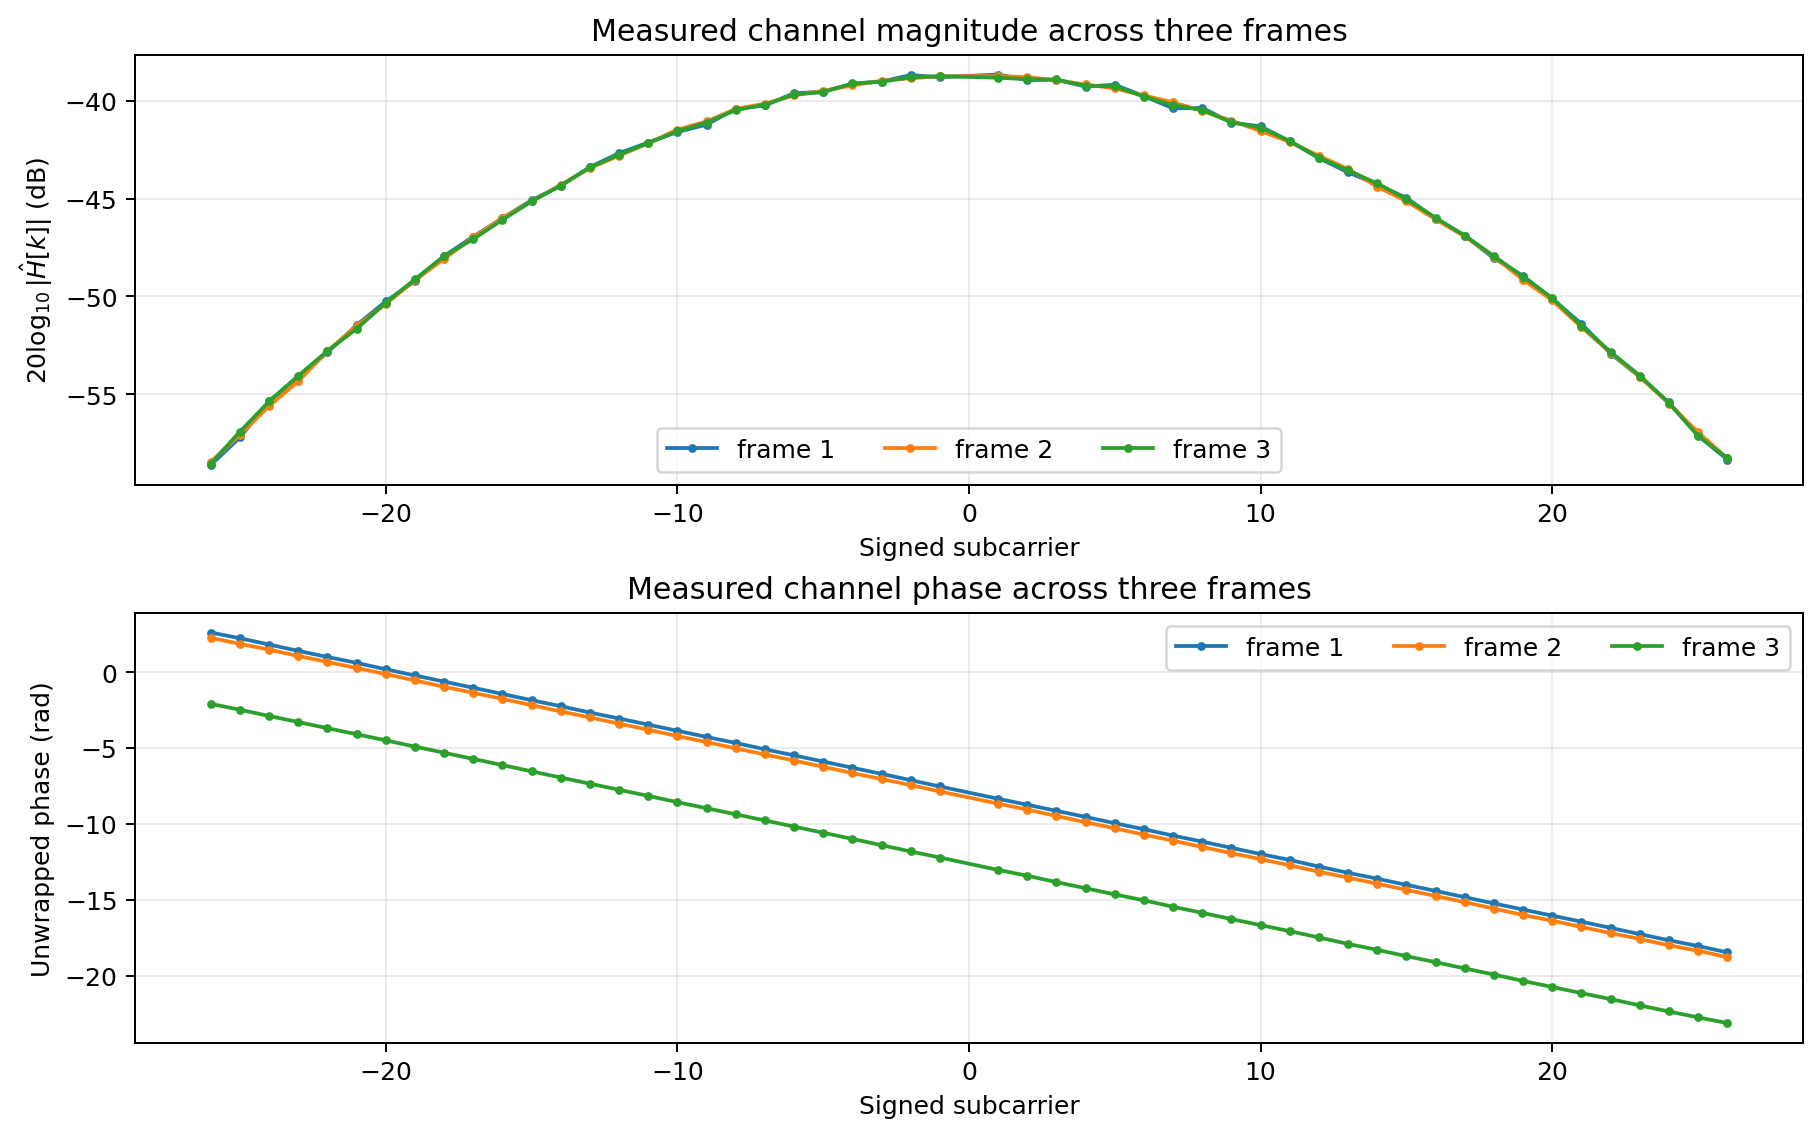

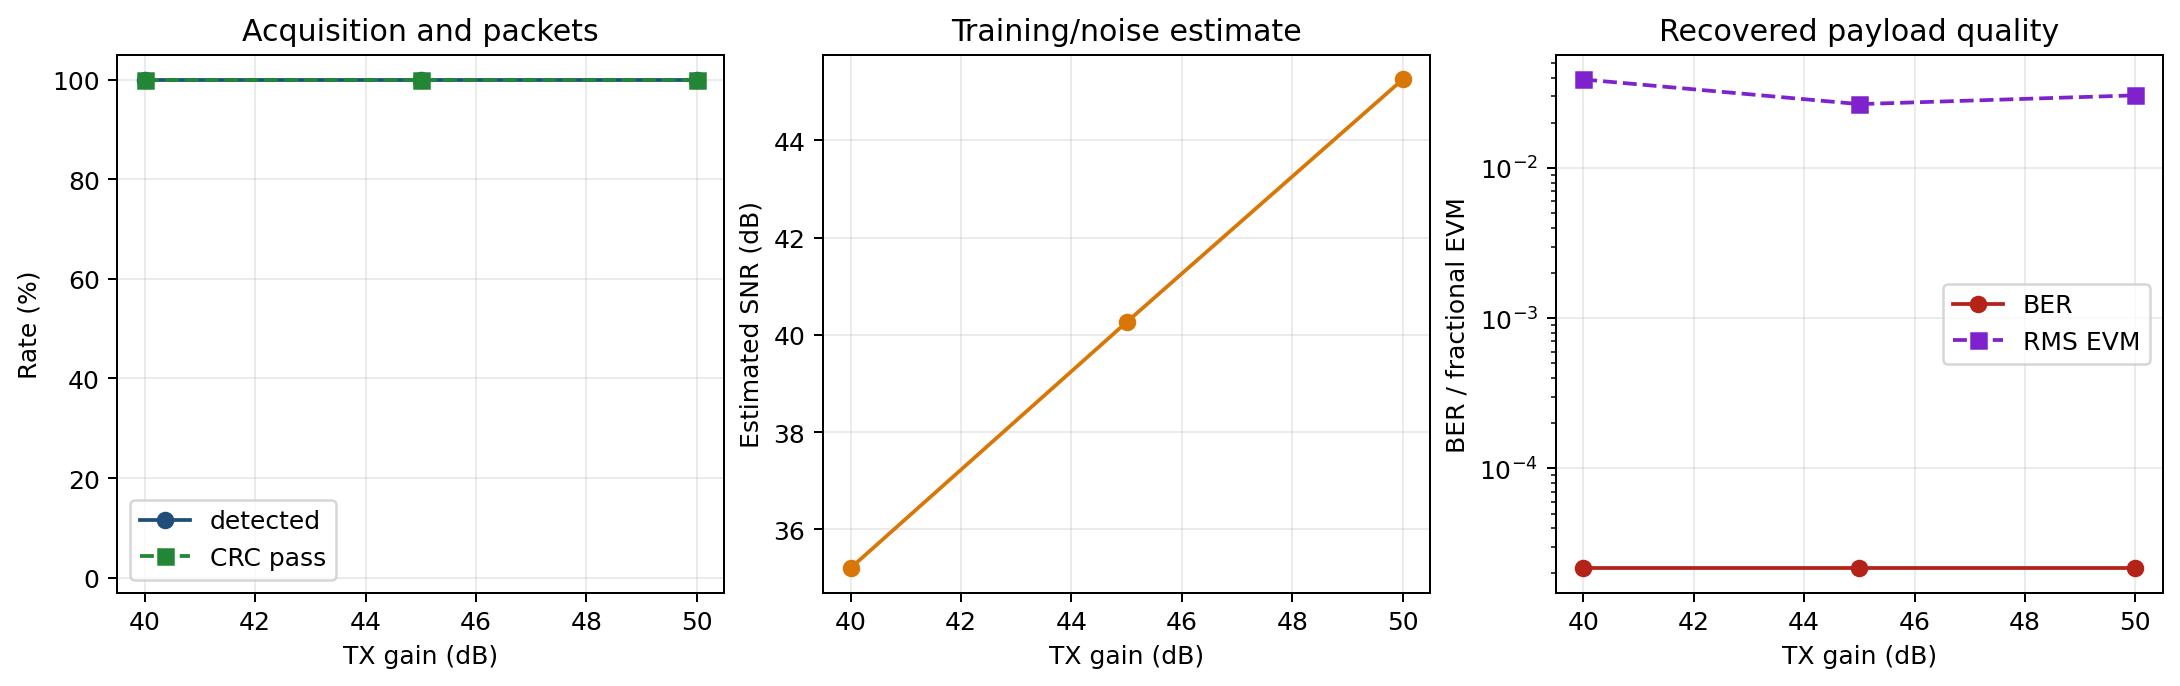

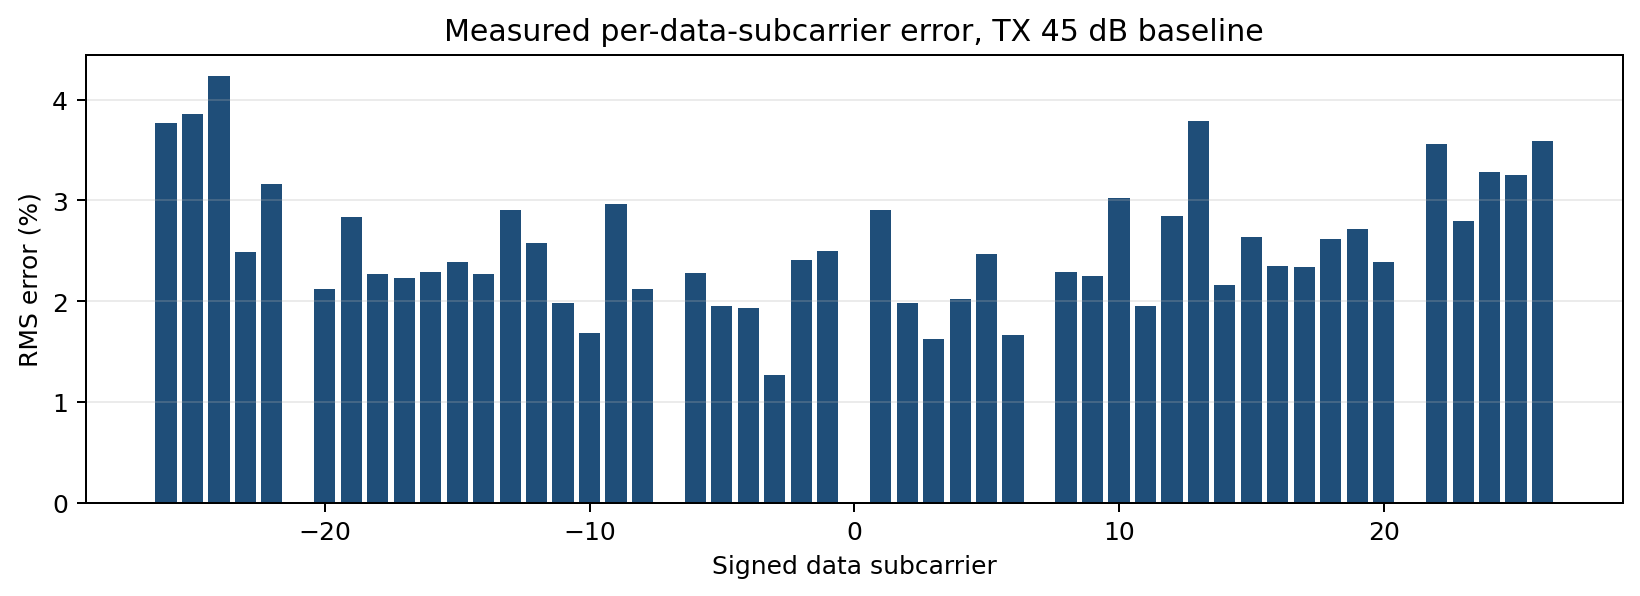

In [9]:
for name in ('task4_hardware_acquisition', 'task4_hardware_constellations', 'task4_hardware_channel_estimates', 'task4_hardware_gain_metrics', 'task4_hardware_subcarrier_error'):
    path = FIGURE_DIR / f"{name}.png"
    display(Image(filename=path))


In [10]:
baseline_gain = tx_gains_db[len(tx_gains_db)//2]
baseline = hardware["gain_results"][f"tx{baseline_gain}"]["aggregate"]
analyzed_frames = baseline["analyzed_frames"]
expected_frames = 12

baseline_detection_rate = analyzed_frames / expected_frames
print("baseline detection rate:", baseline_detection_rate)


baseline detection rate: 1.0


## Report work


<span style="color:#165696"><b>Report.</b> Interpret the measured channel magnitude and phase across subcarriers. </span>

The measured channel magnitude shows a smooth frequency-selective response across the OFDM subcarriers. The channel gain is highest near the center subcarriers (approximately −39 dB) and gradually decreases toward the band edges (approximately −58 dB), indicating that the transmitted signal experiences greater attenuation at the outer frequencies. The nearly identical magnitude responses for the three frames demonstrate that the channel remained stable during the measurement period.

The measured channel phase exhibits an approximately linear decrease with subcarrier index. This linear phase trend is consistent with a fixed propagation delay and timing offset in the channel. The phase responses of the three frames are very similar, showing that the channel characteristics were largely unchanged across the captured packets. Overall, the magnitude and phase plots indicate a stable channel with predictable frequency-dependent gain and phase behavior, which can be effectively compensated through channel estimation and equalization.

<span style="color:#165696"><b>Report.</b> Identify corrupted packets explicitly. An undetected or failed packet is not BER zero. </span>

No corrupted packets were observed for any tested transmit gain. All analyzed frames at 40 dB, 45 dB, and 50 dB were successfully detected and passed CRC, resulting in a packet error rate of 0 and a bit error rate of 0. Since there were no failed or undetected packets, no corrupted packets were identified.

<span style="color:#165696"><b>Report.</b> Explain whether increasing gain improved EVM, CRC success, and channel-power estimates without clipping. </span>

Increasing the transmit gain generally improved the signal quality measurements without causing clipping. The estimated channel power increased monotonically from $1.69\times10^{-5}$ at 40 dB to $5.40\times10^{-5}$ at 45 dB and $1.70\times10^{-4}$ at 50 dB, indicating that a stronger signal was received as gain increased. The estimated SNR also improved from $35.2$ dB to $40.3$ dB and $45.3$ dB.

The EVM improved when the gain was increased from 40 dB to 45 dB, decreasing from $3.88\%$ to $2.66\%$, indicating more accurate symbol recovery. At 50 dB, the EVM increased slightly to $3.04\%$, but it remained better than the 40 dB case. CRC performance did not improve because it was already perfect at all gain settings, with 100% packet detection, 100% CRC success, BER = 0, and PER = 0 for all analyzed frames.

No clipping was observed at any gain level, as the clipped sample count remained zero for every measurement. Therefore, increasing gain increased received power and SNR and generally improved EVM while maintaining perfect packet recovery and avoiding receiver saturation.